In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    roc_auc_score,
    accuracy_score
)

# Configurazione stile visualizzazioni
sns.set_theme(style="whitegrid")

In [4]:
#caricamento del dataset pulito (302 pazienti)
df = pd.read_csv('../data/heart_cleaned.csv')

X = df.drop(columns=['target'])
y = df['target']

#split 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} pazienti")
print(f"Test set: {X_test.shape[0]} pazienti")

Training set: 241 pazienti
Test set: 61 pazienti


In [5]:
#creazione della pipeline (StandardScaler + LogisticRegression)
pipe_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42))
])

#configurazione della Cross-Validation a 5 fold
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#calcolo delle metriche sui 5 fold
cv_results_baseline = cross_validate(
    pipe_baseline, X_train, y_train,
    cv=cv_stratified,
    scoring=['accuracy', 'recall', 'roc_auc']
)

print("Risultati Cross-Validation 5-Fold (Baseline):")
print(f"Accuracy media: {cv_results_baseline['test_accuracy'].mean():.3f} +/- {cv_results_baseline['test_accuracy'].std():.3f}")
print(f"Recall media:   {cv_results_baseline['test_recall'].mean():.3f} +/- {cv_results_baseline['test_recall'].std():.3f}")
print(f"ROC-AUC media:  {cv_results_baseline['test_roc_auc'].mean():.3f} +/- {cv_results_baseline['test_roc_auc'].std():.3f}")

Risultati Cross-Validation 5-Fold (Baseline):
Accuracy media: 0.838 +/- 0.086
Recall media:   0.901 +/- 0.067
ROC-AUC media:  0.914 +/- 0.036


In [7]:
#griglia aggiornata per le versioni recenti di scikit-learn
param_grid = [
    {
        'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'classifier__penalty': ['l2'],
        'classifier__solver': ['lbfgs', 'liblinear']
    },
    {
        'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'classifier__penalty': ['l1'],
        'classifier__solver': ['liblinear', 'saga']
    }
]

#inizializzazione GridSearchCV
grid_search = GridSearchCV(
    estimator=pipe_baseline,
    param_grid=param_grid,
    cv=cv_stratified,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Migliori Iperparametri trovati:")
print(grid_search.best_params_)
print(f"Miglior Recall media in Cross-Validation: {grid_search.best_score_:.3f}")

Migliori Iperparametri trovati:
{'classifier__C': 0.001, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Miglior Recall media in Cross-Validation: 1.000


C:\Users\Jacopo\Desktop\ProgettiPersonali\heart-disease-eda\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


=== CONFRONTO PRESTAZIONI SUL TEST SET ===
Accuracy: 0.754
Recall (Sensibilità): 0.939
ROC-AUC:  0.884



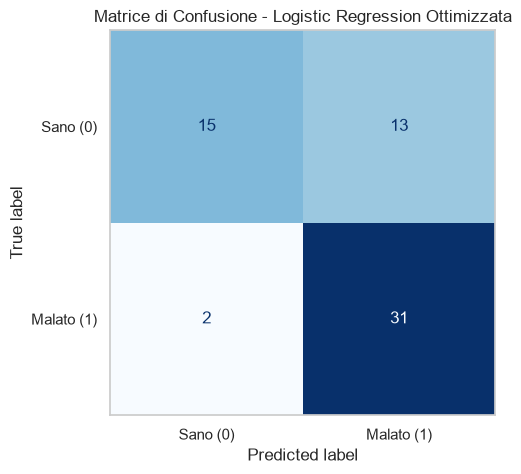

In [8]:
#estrazione del modello migliore identificato da GridSearchCV
best_model = grid_search.best_estimator_

#predizioni sul Test Set
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

#calcolo e stampa delle metriche sul Test Set
test_accuracy = accuracy_score(y_test, y_pred_best)
test_recall = recall_score(y_test, y_pred_best)
test_auc = roc_auc_score(y_test, y_proba_best)

print("=== CONFRONTO PRESTAZIONI SUL TEST SET ===")
print(f"Accuracy: {test_accuracy:.3f}")
print(f"Recall (Sensibilità): {test_recall:.3f}")
print(f"ROC-AUC:  {test_auc:.3f}\n")

#matrice di Confusione
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sano (0)", "Malato (1)"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Matrice di Confusione - Logistic Regression Ottimizzata")
plt.grid(False)
plt.show()

### 📌 Conclusioni dell'Ottimizzazione (Hyperparameter Tuning)

1. **Scelta della Metrica**: Ottimizzando la `GridSearchCV` specificamente sulla **Recall** (`scoring='recall'`), il modello si è adattato alle priorità del dominio clinico.
2. **Impatto sul Test Set**:
   - La **Recall (Sensibilità)** è salita da **0.848** (modello baseline) a **0.939** (+9.1%).
   - L'**Accuracy** si attesta al **75.4%**, accettando un leggero incremento di falsi positivi pur di ridurre al minimo i falsi negativi.
3. **Migliori Iperparametri**: La combinazione `{C: 0.001, penalty: 'l1', solver: 'saga'}` applica una forte regolarizzazione $L_1$ (Lasso), selezionando le feature emodinamiche più stabili ed eliminando il rumore superfluo su un dataset di 302 pazienti.